# LA28 venues and reference polygons (scratch, instructor only)

Goal: list every LA28 venue, see which cities and counties they fall in, and decide which polygon(s) to use as the "reference area" for the urban heat task.

**Sources**

- Venue names, zones and sports: every venue page on https://la28.org/en/games-plan/venues.html, scraped on 2026-11-23. The LA28 pages give **no addresses or coordinates**.
- Coordinates: geocoded with OpenStreetMap's Nominatim from each venue's real name (e.g. "DTLA Arena" = Crypto.com Arena, "2028 Stadium" = SoFi Stadium, "Exposition Park Stadium" = BMO Stadium, "Carson Stadium" = Dignity Health Sports Park). Many venues are temporary, so their points are approximate; see `location_note`.
- Polygons: Census TIGER/Line 2025 places (cities), counties and 2020 urban areas.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from shapely.geometry import shape
from pystac_client import Client
import planetary_computer

pd.set_option('display.max_rows', 60)
pd.set_option('display.max_colwidth', 70)

## All 49 venues

In [2]:
venues = pd.read_csv('data/la28-venues.csv')
venues[['name', 'zone', 'sports', 'socal']]

,name,zone,sports,socal
0,2028 Stadium,Inglewood,Swimming,True
1,Allianz Beach Arena,Long Beach,Beach Volleyball; Blind Football (Soccer),True
2,Belmont Shore,Long Beach,Open Water Swimming; Rowing Coastal Beach Sprints; Sailing,True
3,Carson Courts,Carson,Tennis; Wheelchair Tennis,True
4,Carson Field,Carson,Hockey; Para Archery,True
5,Carson Stadium,Carson,Archery; Rugby Sevens,True
6,Carson Velodrome,Carson,Cycling Track; Para Cycling Track,True
7,Columbus Stadium,Columbus,Football (Soccer),False
8,Comcast Squash Center at Universal Studios,Universal City,Squash,True
9,Dodger Stadium,DTLA,Baseball,True


### Venues outside Southern California

Eight venues are elsewhere: six football (soccer) stadiums plus softball and canoe slalom in Oklahoma City. They are in other Landsat scenes and other climates, so they are out of scope for an LA heat analysis. That leaves **41 Southern California venues**.

In [3]:
venues[~venues['socal']][['name', 'zone', 'sports']]

,name,zone,sports
7,Columbus Stadium,Columbus,Football (Soccer)
28,Nashville Stadium,Nashville,Football (Soccer)
29,New York Stadium,New York,Football (Soccer)
30,OKC Softball Park,OKC,Softball
31,OKC Whitewater Center,OKC,Slalom Paddle
37,San Diego Stadium,San Diego,Football (Soccer)
38,San José Stadium,San José,Football (Soccer)
40,St. Louis Stadium,St. Louis,Football (Soccer)


## Southern California venues

In [4]:
socal = venues[venues['socal']].copy()
socal = gpd.GeoDataFrame(socal,
                         geometry=gpd.points_from_xy(socal['lon'], socal['lat']),
                         crs='epsg:4326')

print('Venues:', len(socal))
print('Distinct locations:', socal.geometry.nunique())

Venues: 41
Distinct locations: 32


Several venues share one point: the three LA Convention Center halls, the four Valley Complexes (Sepulveda Basin), three Carson venues (Dignity Health Sports Park) and three Long Beach Convention Center venues. For a heat analysis these should be **one location each**, or they get counted several times.

How precise each point is:

In [5]:
socal[['name', 'location_note', 'osm_match']]

,name,location_note,osm_match
0,2028 Stadium,venue,"SoFi Stadium, 1001, Champions Way, Hollywood Park, Morningside Par..."
1,Allianz Beach Arena,approximate: LA28 says westernmost edge of the beach next to downt...,"Long Beach City Beach, Long Beach, Los Angeles County, California"
2,Belmont Shore,approximate: neighborhood/waterfront,"Belmont Shore, Long Beach, Los Angeles County, California, 90803, ..."
3,Carson Courts,sports complex (shared point),"Dignity Health Sports Park, 18400, South Avalon Boulevard, Carson,..."
4,Carson Field,sports complex (shared point),"Dignity Health Sports Park, 18400, South Avalon Boulevard, Carson,..."
5,Carson Stadium,sports complex (shared point),"Dignity Health Sports Park, 18400, South Avalon Boulevard, Carson,..."
6,Carson Velodrome,venue,"VELO Sports Center, East University Drive, Carson, Los Angeles Cou..."
8,Comcast Squash Center at Universal Studios,approximate: temporary venue on studio lot,"Universal Studios Hollywood, 100, Universal Hollywood Drive, Unive..."
9,Dodger Stadium,venue,"Dodger Stadium, 1000, Vin Scully Avenue, Chinatown, Los Angeles, L..."
10,DTLA Arena,venue,"Crypto.com Arena, 1111, South Figueroa Street, South Park, Downtow..."


Venues to double-check on a map: Allianz Beach Arena (LA28 only says "westernmost edge of the coastline, next to downtown"), the Port of Los Angeles (sailing on open water: a land point doesn't represent it), Trestles (a surf break), and the road-cycling starts at Griffith Observatory and the LA Zoo (the course is a line, not a point).

## Which cities and counties?

In [6]:
places = gpd.read_file('data/tl_2025_06_place.zip').to_crs('epsg:4326')
counties = gpd.read_file('data/tl_2025_us_county.zip')
counties = counties[counties['STATEFP'] == '06'].to_crs('epsg:4326')

socal = (socal
         .sjoin(places[['NAME', 'geometry']].rename(columns={'NAME': 'city'}), how='left')
         .drop(columns='index_right')
         .sjoin(counties[['NAME', 'geometry']].rename(columns={'NAME': 'county'}), how='left')
         .drop(columns='index_right'))
socal['city'] = socal['city'].fillna('(unincorporated)')

socal[['name', 'zone', 'city', 'county']]

,name,zone,city,county
0,2028 Stadium,Inglewood,Inglewood,Los Angeles
1,Allianz Beach Arena,Long Beach,Long Beach,Los Angeles
2,Belmont Shore,Long Beach,Long Beach,Los Angeles
3,Carson Courts,Carson,Carson,Los Angeles
4,Carson Field,Carson,Carson,Los Angeles
5,Carson Stadium,Carson,Carson,Los Angeles
6,Carson Velodrome,Carson,Carson,Los Angeles
8,Comcast Squash Center at Universal Studios,Universal City,(unincorporated),Los Angeles
9,Dodger Stadium,DTLA,Los Angeles,Los Angeles
10,DTLA Arena,DTLA,Los Angeles,Los Angeles


In [7]:
socal.groupby(['county', 'city']).size().rename('n_venues').reset_index()

,county,city,n_venues
0,Los Angeles,(unincorporated),2
1,Los Angeles,Arcadia,1
2,Los Angeles,Carson,4
3,Los Angeles,Industry,1
4,Los Angeles,Inglewood,2
5,Los Angeles,Long Beach,7
6,Los Angeles,Los Angeles,19
7,Los Angeles,Pasadena,2
8,Los Angeles,Pomona,1
9,Orange,Anaheim,1


**Summary:** 19 of 41 venues are in the City of Los Angeles. The rest are in 8 other cities (Long Beach, Carson, Inglewood, Pasadena, Arcadia, Pomona, Industry, Anaheim), two unincorporated parts of LA County (Universal City, Whittier Narrows) and Trestles, in unincorporated San Diego County. Anaheim is in Orange County.

## Landsat coverage

In [8]:
catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                      modifier=planetary_computer.sign_inplace)
items = catalog.search(collections=['landsat-c2-l2'],
                       bbox=list(socal.total_bounds),
                       datetime='2026-08-21/2026-08-22').item_collection()

footprints = gpd.GeoDataFrame({'id': [i.id for i in items]},
                              geometry=[shape(i.geometry) for i in items],
                              crs='epsg:4326')
footprints['n_venues'] = [socal.within(g).sum() for g in footprints.geometry]
footprints[['id', 'n_venues']]

,id,n_venues
0,LC09_L2SP_040037_20260822_02_T1,4
1,LC09_L2SP_040036_20260822_02_T1,2
2,LC08_L2SP_041037_20260821_02_T1,17
3,LC08_L2SP_041036_20260821_02_T1,40


One scene (path 041, row 036) covers 40 of the 41 venues: everything except Trestles State Beach. Adding Trestles would mean merging two scenes, from two different days, which we haven't covered in class.

## Map: venues, host cities and counties

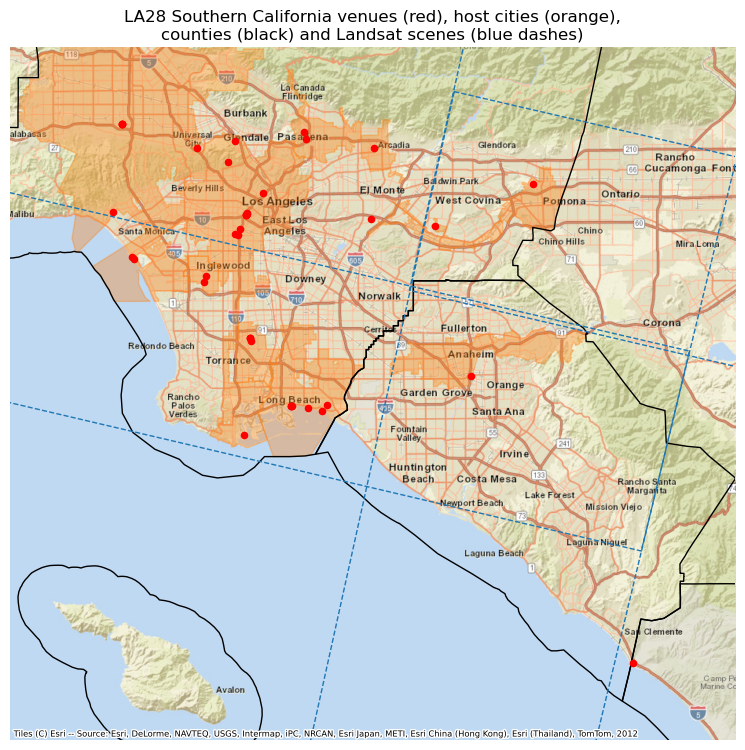

In [9]:
host_cities = places[places['NAME'].isin(socal['city'])]
socal_counties = counties[counties['NAME'].isin(['Los Angeles', 'Orange', 'San Diego'])]

fig, ax = plt.subplots(figsize=(10, 9))
socal_counties.to_crs(3857).boundary.plot(ax=ax, color='black', linewidth=1)
host_cities.to_crs(3857).plot(ax=ax, color='tab:orange', alpha=0.35, edgecolor='tab:orange')
footprints.to_crs(3857).boundary.plot(ax=ax, color='tab:blue', linestyle='--', linewidth=1)
socal.to_crs(3857).plot(ax=ax, color='red', markersize=20, zorder=3)

xmin, ymin, xmax, ymax = socal.to_crs(3857).total_bounds
ax.set_xlim(xmin - 20000, xmax + 20000)
ax.set_ylim(ymin - 15000, ymax + 15000)
ctx.add_basemap(ax, crs='epsg:3857', source=ctx.providers.Esri.WorldStreetMap, attribution_size=6)
ax.set_title('LA28 Southern California venues (red), host cities (orange),\n'
             'counties (black) and Landsat scenes (blue dashes)')
ax.set_axis_off()
plt.show()

## Options for the reference polygon

The heat task compares the surface temperature around venues to a reference area. Choices:

| Option | Polygons | Venues covered | Pros | Cons |
|---|---|---|---|---|
| A. City of Los Angeles only | 1 | 19 of 41 | Simplest; matches the current scratch notebook | Leaves out more than half the venues; TIGER boundary includes ocean |
| B. Each venue's host city | 9 cities + unincorporated areas | 38 of 41 (no polygon for the 3 unincorporated) | "Is this venue hotter than its own city?" is a fair local comparison | 9+ polygons and a loop; small cities give noisy averages; unincorporated venues need another rule |
| C. LA County | 1 | 39 of 41 (not Anaheim or Trestles) | One polygon | Includes mountains, Mojave Desert, and Catalina and San Clemente islands: not a fair comparison for urban venues; only 88% of it is in the Landsat scene |
| D. Census urban area "Los Angeles–Long Beach–Anaheim" | 1 | 38 of 41 | One polygon; the Census defines urban areas as densely developed territory, which is what we want to compare to; includes Anaheim; 99% inside one Landsat scene | Excludes Griffith Park (so Griffith Observatory and the LA Zoo fall outside) and Trestles; a less familiar dataset for students |

In [10]:
urban = gpd.read_file('data/tl_2025_us_uac20.zip')
urban = urban[urban['NAME20'] == 'Los Angeles--Long Beach--Anaheim, CA'].to_crs('epsg:4326')

socal['in_urban_area'] = socal.within(urban.geometry.iloc[0])
print('Venues inside the urban area:', socal['in_urban_area'].sum(), 'of', len(socal))
socal.loc[~socal['in_urban_area'], ['name', 'city', 'county']]

Venues inside the urban area: 38 of 41


,name,city,county
14,Griffith Observatory,Los Angeles,Los Angeles
22,LA Zoo,Los Angeles,Los Angeles
41,Trestles State Beach,(unincorporated),San Diego


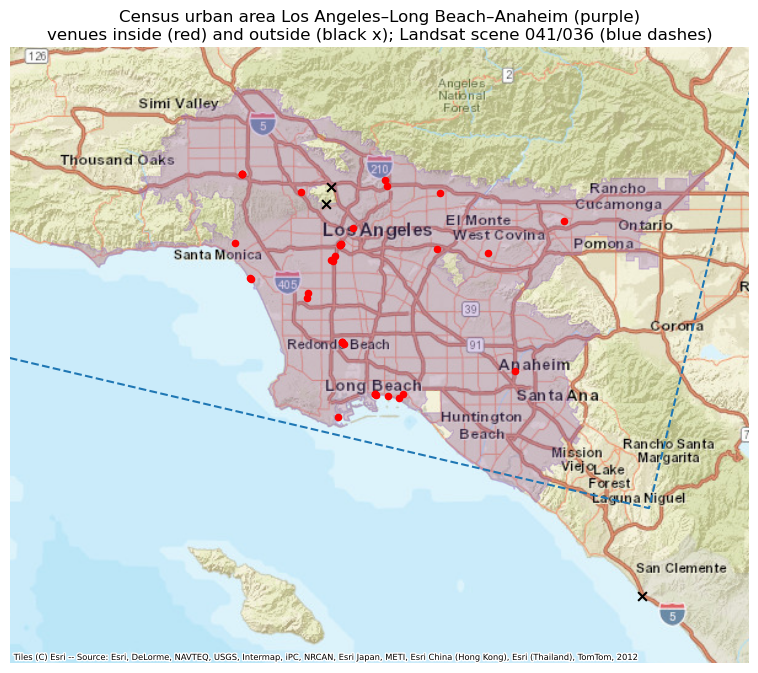

In [11]:
fig, ax = plt.subplots(figsize=(10, 8))
urban.to_crs(3857).plot(ax=ax, color='tab:purple', alpha=0.3, edgecolor='tab:purple')
socal[socal['in_urban_area']].to_crs(3857).plot(ax=ax, color='red', markersize=20, zorder=3)
socal[~socal['in_urban_area']].to_crs(3857).plot(ax=ax, color='black', marker='x', markersize=40, zorder=3)
footprints[footprints['id'].str.contains('041036')].to_crs(3857).boundary.plot(ax=ax, color='tab:blue', linestyle='--')

xmin, ymin, xmax, ymax = urban.to_crs(3857).total_bounds
ax.set_xlim(xmin - 10000, xmax + 10000)
ax.set_ylim(ymin - 40000, ymax + 10000)
ctx.add_basemap(ax, crs='epsg:3857', source=ctx.providers.Esri.WorldStreetMap, attribution_size=6)
ax.set_title('Census urban area Los Angeles–Long Beach–Anaheim (purple)\n'
             'venues inside (red) and outside (black x); Landsat scene 041/036 (blue dashes)')
ax.set_axis_off()
plt.show()

## Recommendation

**Option D, the Census urban area**, with this justification for students:

> *We want to know whether the ground around venues is hotter than the urban region the Games take place in. The Census defines urban areas as densely developed territory, so the urban area's average temperature represents "the city" as people experience it, without mountains, desert or ocean pulling the average down.*

Scope rules that come with it:

1. Keep the 38 venues inside the urban area, with shared locations merged into one point each.
2. Leave out Trestles (another scene, another county) and the road-cycling starts in Griffith Park (they're in parkland, and the event is a course, not a venue). Students can be told this or asked to find it.
3. Treat the Port of Los Angeles and Belmont Shore (water events) with care, or drop them: the heat question is about spectators on land.

Option B is a richer student exercise ("hotter than its own city?") but adds a loop over 9 cities and a rule for unincorporated areas, which goes against keeping it simple.

# Cross-reference with Wikipedia: permanent LA-area facilities only

Source: [Venues of the 2028 Summer Olympics and Paralympics](https://en.wikipedia.org/wiki/Venues_of_the_2028_Summer_Olympics_and_Paralympics), wikitext downloaded 2026-11-23. Wikipedia gives each venue a **status**: *Existing*, *Existing with temporary stands*, *Existing, expanded* or *Temporary*.

Rules used here:

1. **Keep** *Existing*, *Existing with temporary stands* and *Existing, expanded*: the facility (and its surface) is there today, which is what Landsat sees.
2. **Drop** *Temporary* venues: Landsat can't see something that isn't built yet, and most temporary venues are on parks, beaches or parking lots.
3. **LA area only**: drop Trestles (San Clemente, another Landsat scene) and everything outside Southern California. Honda Center (Anaheim, Orange County) is kept as part of Greater LA; it's inside the Census urban area.
4. One row per **facility**, not per LA28 venue name: the three Convention Center halls are one facility.

In [12]:
# LA28 venue name -> (Wikipedia facility name, Wikipedia status, keep?, note)
crossref = {
 'Carson Stadium':  ('Dignity Health Sports Park, Main Stadium', 'Existing', True, ''),
 'Carson Courts':   ('Dignity Health Sports Park, Tennis Stadium', 'Existing', True, 'Shares a point with Carson Stadium (same complex)'),
 'Carson Velodrome':('Velo Sports Center', 'Existing', True, ''),
 'Carson Field':    ('Dignity Health Sports Park, Track and Field Facility', 'Temporary', False, ''),
 'DTLA Arena':      ('Crypto.com Arena', 'Existing', True, ''),
 'Dodger Stadium':  ('Dodger Stadium', 'Existing', True, ''),
 'LA Convention Center Hall 1': ('Los Angeles Convention Center', 'Existing with temporary stands', True, 'Halls 1-3 are one facility. Wikipedia: use depends on a $2.6B expansion'),
 'LA Convention Center Hall 2': ('Los Angeles Convention Center', 'Existing with temporary stands', False, 'Same facility as Hall 1'),
 'LA Convention Center Hall 3': ('Los Angeles Convention Center', 'Existing with temporary stands', False, 'Same facility as Hall 1'),
 'Peacock Theater': ('Peacock Theater', 'Existing', True, ''),
 'Exposition Park Stadium': ('BMO Stadium', 'Existing', True, ''),
 'Galen Center':    ('Galen Center', 'Existing', True, ''),
 'LA Memorial Coliseum': ('Los Angeles Memorial Coliseum', 'Existing', True, ''),
 '2028 Stadium':    ('SoFi Stadium', 'Existing (swimming: with temporary stands)', True, ''),
 'Intuit Dome':     ('Intuit Dome', 'Existing', True, ''),
 'Long Beach Arena':('Long Beach Arena', 'Existing', True, ''),
 'Long Beach Target Shooting Hall': ('Long Beach Convention Center', 'Temporary', False, 'Inside an existing building, but Wikipedia lists the venue as temporary'),
 'Long Beach Aquatics Center':  ('Long Beach Convention Center Lot', 'Temporary', False, ''),
 'Long Beach Climbing Theater': ('Long Beach Convention Center Lot', 'Temporary', False, ''),
 'Allianz Beach Arena': ('Alamitos Beach', 'Temporary', False, ''),
 'Belmont Shore':   ('Belmont Veterans Memorial Pier / Long Beach Waterfront', 'Existing with temporary stands (pier) / Temporary (waterfront)', True,
                     'LA28 groups three events; Wikipedia splits them. Kept as the pier (kite and windfoil sailing). Water venue'),
 'Marine Stadium':  ('Long Beach Marine Stadium', 'Existing with temporary stands', True, 'Water venue (rowing, canoe sprint)'),
 'Port of Los Angeles': ('Port of Los Angeles', 'Existing with temporary stands', True, 'Water venue (sailing in the harbor)'),
 'Valley Complex 1': ('Sepulveda Basin Recreation Area', 'Temporary', False, ''),
 'Valley Complex 2': ('Sepulveda Basin Recreation Area', 'Temporary', False, ''),
 'Valley Complex 3': ('Sepulveda Basin Recreation Area', 'Temporary', False, ''),
 'Valley Complex 4': ('Sepulveda Basin Recreation Area', 'Temporary', False, ''),
 'Fairgrounds Cricket Stadium': ('Knight Riders Cricket Ground (Fairplex)', 'Existing, expanded', True,
                     'LA28 calls it "purpose-built"; Wikipedia says an existing ground, expanded'),
 'Griffith Observatory': ('Griffith Observatory', 'Temporary', False, 'Road cycling finish'),
 'LA Zoo':          ('Los Angeles Zoo', 'Temporary', False, 'Road cycling start/finish'),
 'Honda Center':    ('Honda Center', 'Existing', True, 'Anaheim, Orange County'),
 'Industry Hills MTB Course': ('Industry Hills Mountain Bike Course', 'Temporary', False, ''),
 'Whittier Narrows Clay Shooting Center': ('LA Clays Shooting Sports Park', 'Existing', True, 'Point is approximate (recreation area); OSM has no match for LA Clays'),
 'Riviera Country Club': ('Riviera Country Club', 'Existing', True, ''),
 'Rose Bowl Stadium': ('Rose Bowl', 'Existing', True, ''),
 'Rose Bowl Aquatics Center': ('Rose Bowl Aquatics Center', 'Existing with temporary stands', True, ''),
 'Santa Anita Park': ('Santa Anita Park', 'Existing with temporary stands', True, ''),
 'Trestles State Beach': ('Trestles', 'Temporary', False, 'Also outside the LA area (San Clemente)'),
 'Comcast Squash Center at Universal Studios': ('Universal Studios Lot', 'Existing with temporary stands', False,
                     'CONFLICT: LA28 says "temporary, purpose-built" squash center; Wikipedia says existing. Dropped, following LA28'),
 'Venice Beach':    ('Venice Beach', 'Temporary', False, ''),
 'Venice Beach Boardwalk': ('Venice Beach', 'Temporary', False, ''),
}

# Every Southern California LA28 venue is matched
assert set(crossref) == set(socal['name'])

xref = pd.DataFrame.from_dict(crossref, orient='index',
                              columns=['wiki_name', 'wiki_status', 'keep', 'note'])
socal = socal.join(xref, on='name')
socal[['name', 'wiki_name', 'wiki_status', 'keep', 'note']]

,name,wiki_name,wiki_status,keep,note
0,2028 Stadium,SoFi Stadium,Existing (swimming: with temporary stands),True,
1,Allianz Beach Arena,Alamitos Beach,Temporary,False,
2,Belmont Shore,Belmont Veterans Memorial Pier / Long Beach Waterfront,Existing with temporary stands (pier) / Temporary (waterfront),True,LA28 groups three events; Wikipedia splits them. Kept as the pier ...
3,Carson Courts,"Dignity Health Sports Park, Tennis Stadium",Existing,True,Shares a point with Carson Stadium (same complex)
4,Carson Field,"Dignity Health Sports Park, Track and Field Facility",Temporary,False,
5,Carson Stadium,"Dignity Health Sports Park, Main Stadium",Existing,True,
6,Carson Velodrome,Velo Sports Center,Existing,True,
8,Comcast Squash Center at Universal Studios,Universal Studios Lot,Existing with temporary stands,False,"CONFLICT: LA28 says ""temporary, purpose-built"" squash center; Wiki..."
9,Dodger Stadium,Dodger Stadium,Existing,True,
10,DTLA Arena,Crypto.com Arena,Existing,True,


### On Wikipedia but not on the LA28 venue list

These are not on the LA28 venues page, so they weren't scraped. None is a competition venue except Grand Park, which Wikipedia marks "citation needed" and as temporary.

| Wikipedia facility | Use | Status |
|---|---|---|
| Grand Park (DTLA) | Race walking | Temporary, *citation needed* |
| NFL Los Angeles at Hollywood Park (Inglewood) | Main Press Center | Existing |
| UCLA student housing (Westwood) | Olympic Village | Existing |
| Warner Bros. Ranch (Burbank) | International Broadcast Centre | Existing |

The Olympic Village could be worth adding: athletes live there for weeks, so heat matters as much as at venues.

## Permanent LA-area facilities

In [13]:
# Better point for Belmont: the pier itself (OpenStreetMap)
socal.loc[socal['name'] == 'Belmont Shore', 'geometry'] = gpd.points_from_xy([-118.14850], [33.75665], crs='epsg:4326')

facilities = socal[socal['keep']].copy()
facilities['water_venue'] = facilities['note'].str.contains('Water venue')

print('Permanent LA-area facilities:', len(facilities))
print('Water venues among them:', facilities['water_venue'].sum())
facilities[['wiki_name', 'sports', 'city', 'wiki_status', 'water_venue']]

Permanent LA-area facilities: 23
Water venues among them: 3


,wiki_name,sports,city,wiki_status,water_venue
0,SoFi Stadium,Swimming,Inglewood,Existing (swimming: with temporary stands),False
2,Belmont Veterans Memorial Pier / Long Beach Waterfront,Open Water Swimming; Rowing Coastal Beach Sprints; Sailing,Long Beach,Existing with temporary stands (pier) / Temporary (waterfront),True
3,"Dignity Health Sports Park, Tennis Stadium",Tennis; Wheelchair Tennis,Carson,Existing,False
5,"Dignity Health Sports Park, Main Stadium",Archery; Rugby Sevens,Carson,Existing,False
6,Velo Sports Center,Cycling Track; Para Cycling Track,Carson,Existing,False
9,Dodger Stadium,Baseball,Los Angeles,Existing,False
10,Crypto.com Arena,Artistic Gymnastics; Boxing; Trampoline Gymnastics; Wheelchair Bas...,Los Angeles,Existing,False
11,BMO Stadium,Flag Football; Lacrosse,Los Angeles,Existing,False
12,Knight Riders Cricket Ground (Fairplex),Cricket,Pomona,"Existing, expanded",False
13,Galen Center,Badminton; Para Badminton; Rhythmic Gymnastics; Wheelchair Rugby,Los Angeles,Existing,False


In [14]:
facilities['in_urban_area'] = facilities.within(urban.geometry.iloc[0])
print('Inside the Census urban area:', facilities['in_urban_area'].sum(), 'of', len(facilities))
facilities.loc[~facilities['in_urban_area'], ['wiki_name', 'city']]

Inside the Census urban area: 22 of 23


,wiki_name,city
2,Belmont Veterans Memorial Pier / Long Beach Waterfront,Long Beach


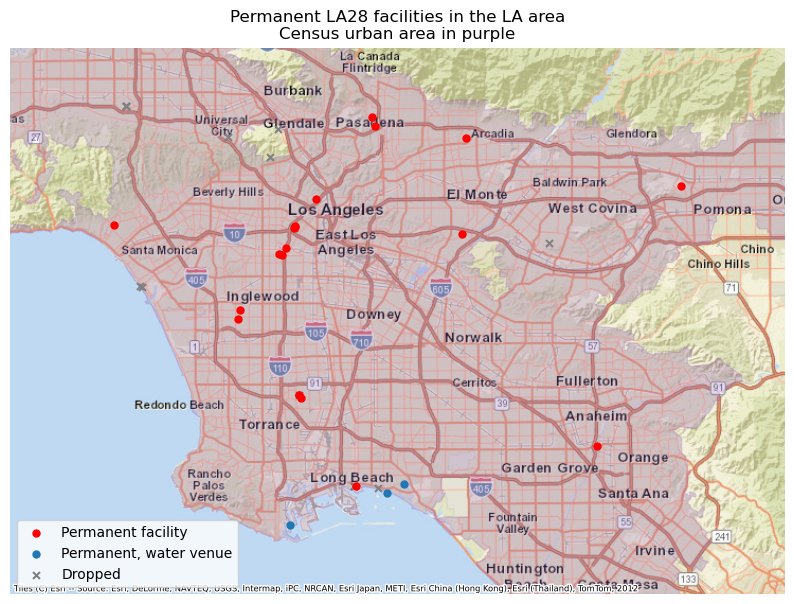

In [15]:
fig, ax = plt.subplots(figsize=(10, 8))
urban.to_crs(3857).plot(ax=ax, color='tab:purple', alpha=0.25, edgecolor='tab:purple')
land = facilities[~facilities['water_venue']].to_crs(3857)
water = facilities[facilities['water_venue']].to_crs(3857)
land.plot(ax=ax, color='red', markersize=25, zorder=3, label='Permanent facility')
water.plot(ax=ax, color='tab:blue', markersize=25, zorder=3, label='Permanent, water venue')
socal[~socal['keep']].to_crs(3857).plot(ax=ax, color='gray', marker='x', markersize=25, zorder=2, label='Dropped')

xmin, ymin, xmax, ymax = facilities.to_crs(3857).total_bounds
ax.set_xlim(xmin - 15000, xmax + 15000)
ax.set_ylim(ymin - 10000, ymax + 10000)
ctx.add_basemap(ax, crs='epsg:3857', source=ctx.providers.Esri.WorldStreetMap, attribution_size=6)
ax.legend(loc='lower left')
ax.set_title('Permanent LA28 facilities in the LA area\nCensus urban area in purple')
ax.set_axis_off()
plt.show()

In [16]:
# Save for the heat notebook
(facilities[['name', 'wiki_name', 'sports', 'city', 'county', 'wiki_status', 'water_venue', 'note', 'geometry']]
 .to_file('data/la28-permanent-facilities.geojson', driver='GeoJSON'))